# Milestone 1 — Dataset Integration and Post-Join Cleaning
**Data Engineering and Visualization — Winter 2026**
**Author:** Member 3 (Dataset integration and post-join cleaning)

## 1. Overview and integration plan

| Item | Housing side | Transportation side |
|---|---|---|
| Dataset | DOB NOW: Build – Job Application Filings (catalog H5) | SIRTA – Serious Injury Response, Tracking & Analysis Program (catalog T4) |
| Dataset ID / link | `w9ak-ipjd` — https://data.cityofnewyork.us/resource/w9ak-ipjd | `xeqp-qz8h` — https://data.cityofnewyork.us/Transportation/Serious-Injury-Response-Tracking-Analysis-Program-/xeqp-qz8h |
| Cleaned input (Members 1 and 2) | `housing_clean.csv` (one row per job) | `sirta_clean.csv` (one row per crash) |
| Unit of observation | One construction job filing | One crash with at least one severe injury or fatality |
| Geography available | Borough, ZIP, community board, council district, lat/lon | Borough, precinct, community board (24%), ZIP (60%), lat/lon (82%) |
| Time available | Filing date | Crash date |

### Integration decision
**Join key: community district (59 areas) x month (`year_month`), 2022-01 to the last complete month of SIRTA.**
Two companion tables are produced from the same inputs: a **district total** table (one row per district) and a **borough x month** table.

**Why community district?**
* It is the only geography that both datasets carry directly, and it is an official administrative unit, so results can be explained to the people who use them (community boards, DOT, city planners).
* There are only 59 of them, so each area has enough crashes to avoid the extreme noise of ZIP x month cells (SIRTA only records crashes with a severe injury or death, so counts per small area per month are tiny).
* Housing has the district for 99.3% of filings (99.9% for new buildings), so the weak side is transportation, not housing.

**Alternatives considered**

| Alternative | Why not the main level |
|---|---|
| ZIP x month | 154+ areas, mostly 0 or 1 crash per cell; 40% of SIRTA crashes have no ZIP. ZIP areas also do not match planning or DOT boundaries. |
| Borough x month | Complete for every crash (including fatal ones) but only 5 areas, too coarse for spatial patterns. **Kept as a companion table.** |
| Census tract | About 2,300 areas, far too sparse; only 26% of crashes carry a tract. |
| Row-level / spatial proximity join | The brief says not to join row to row just because a common attribute exists. Used only to *assign* a district to crashes, never to link a crash to a specific building. |

**Known weakness of the transportation data (drives the design):** fatal crashes rarely carry coordinates or a community board (see Section 5), so they are under-represented in any district-level table. The borough x month table is the only one that contains them all.

### Prompts used
*(The project requires listing the prompts. Keep adding yours here.)*
1. "I am member 3 (dataset integration and post-join cleaning)."
2. "this is sirta_clean.csv and this is the housing_clean.csv."

## 2. Setup
All settings live in one cell so the team can change them in one place.

In [8]:
!pip install geopandas

In [9]:
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.spatial import cKDTree
from IPython.display import display

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:,.2f}".format)

# ---------------- Configuration ----------------
HOUSING_FILE = "housing_clean.csv"          # Member 1 output
SIRTA_FILE = "sirta_clean.csv"              # Member 2 output
BOUNDARY_FILE = "community_districts.geojson"   # optional local copy of the CD boundaries (see 5.2)
PANEL_START = "2022-01"                     # SIRTA starts in 2022-01; also the first reliable DOB NOW new-building year
ASSIGN_MAX_M = 300                          # nearest-filing fallback: max distance (metres) to copy a district
USE_NEAREST_FILING_FALLBACK = True          # layer 3 of the district assignment (5.3)
LARGE_PIPELINE_K = 3.0                      # IQR multiplier for flagging very large construction months
LAG_MONTHS = range(0, 7)                    # lags tested in research question 2

# NYC Open Data "Community Districts" boundaries (dataset 5crt-au7u); tried in order if no local file exists
BOUNDARY_URLS = [
    "https://data.cityofnewyork.us/api/geospatial/5crt-au7u?method=export&format=GeoJSON",
    "https://data.cityofnewyork.us/api/v3/views/5crt-au7u/query.geojson?accessType=DOWNLOAD",
]

# Where inputs live / where outputs go (project structure: notebooks/, outputs/, src/, website/, docs/)
SEARCH_DIRS = [Path("../outputs"), Path("../data"), Path("."), Path("outputs"), Path("/content")]
OUT_DIR = Path("../outputs") if Path("../outputs").exists() else Path("outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

def find_file(name):
    """Look for an input file in the usual project folders."""
    for folder in SEARCH_DIRS:
        if (folder / name).exists():
            return folder / name
    raise FileNotFoundError(f"{name} not found in {[str(d) for d in SEARCH_DIRS]}. Put it in outputs/ or edit SEARCH_DIRS.")

# ---------------- Shared lookups (identical to Members 1 and 2 so keys match) ----------------
CD_COUNT = {1: 12, 2: 12, 3: 18, 4: 14, 5: 3}    # residential community districts per borough
BOROUGH_CODE = {1: "MANHATTAN", 2: "BRONX", 3: "BROOKLYN", 4: "QUEENS", 5: "STATEN ISLAND"}
VALID_CDS = sorted(b * 100 + n for b, count in CD_COUNT.items() for n in range(1, count + 1))
assert len(VALID_CDS) == 59

def normalize_community_board(series):
    """Keep only real residential community districts (borough digit + CD 01..max for that borough).
    Park / joint-interest codes (e.g. 164, 355, 481) and impossible codes (e.g. 7502) become missing."""
    cb = pd.to_numeric(series, errors="coerce")
    boro_digit, cd_number = cb // 100, cb % 100
    valid = boro_digit.isin(list(CD_COUNT)) & (cd_number >= 1) & (cd_number <= boro_digit.map(CD_COUNT))
    return cb.where(valid).astype("Int64")

def borough_of_cd(cd_series):
    """Borough name implied by the first digit of a community district code."""
    return (cd_series.astype("Int64") // 100).map(BOROUGH_CODE)

## 3. Load the cleaned inputs
We start from the two files produced by Members 1 and 2 so the whole team works on identical data. `zip_code` is read as text because it was saved as a float (`10001.0`) in the housing file.

In [10]:
housing = pd.read_csv(find_file(HOUSING_FILE), low_memory=False, dtype={"zip_code": "string"})
housing["zip_code"] = housing["zip_code"].str.replace(r"\.0$", "", regex=True)

# Coerce year_month to string in case it was saved as a mixed type, and drop undatable rows
housing["year_month"] = housing["year_month"].astype(str).str.strip()
housing = housing[housing["year_month"].str.match(r"^\d{4}-\d{2}$", na=False)]

sirta = pd.read_csv(find_file(SIRTA_FILE), low_memory=False)
sirta["year_month"] = sirta["year_month"].astype(str).str.strip()
sirta = sirta[sirta["year_month"].str.match(r"^\d{4}-\d{2}$", na=False)]

print(f"Housing: {housing.shape[0]:,} rows x {housing.shape[1]} columns | filing months {housing.year_month.min()} to {housing.year_month.max()}")
print(f"SIRTA:   {sirta.shape[0]:,} rows x {sirta.shape[1]} columns | crash months {sirta.year_month.min()} to {sirta.year_month.max()}")

# The panel ends at the last month of SIRTA
END_MONTH = sirta["year_month"].max()
monthly = sirta.groupby("year_month").size()
print(f"\nPanel window: {PANEL_START} to {END_MONTH}")
print(f"Crashes in last month: {monthly.iloc[-1]} (median of other months: {monthly.iloc[:-1].median():.0f}) "
      "-> if the last month is far below the median, set END_MONTH to the previous month.")

Housing: 547,928 rows x 22 columns | filing months 2019-01 to 2026-10
SIRTA:   13,307 rows x 28 columns | crash months 2022-01 to 2026-06

Panel window: 2022-01 to 2026-06
Crashes in last month: 316 (median of other months: 254) -> if the last month is far below the median, set END_MONTH to the previous month.


## 4. Check and finish the community-district key on the housing side

Member 1 kept `community_board` as a float. Before joining we make sure it is a real, comparable key:
* only the **59 residential districts** are valid; park / joint-interest codes (e.g. 164, 355, 481-484, 595) and impossible codes (505, 7502) are set to missing;
* the borough digit must agree with the filing's borough; contradictions are set to missing (not guessed).

Filings without a valid district are **not dropped from the data**; they simply cannot be placed in a district table. They are still counted in the borough x month table.

In [11]:
housing["community_district"] = normalize_community_board(housing["community_board"])

# Borough implied by the district vs the filing's own borough
conflict = housing["community_district"].notna() & (borough_of_cd(housing["community_district"]) != housing["borough"])
housing.loc[conflict, "community_district"] = pd.NA

new_buildings_all = housing[housing["is_new_building"]]
key_quality = pd.DataFrame({
    "all filings": [len(housing), housing["community_board"].notna().sum(),
                    (housing["community_board"].notna() & normalize_community_board(housing["community_board"]).isna()).sum(),
                    conflict.sum(), housing["community_district"].notna().sum()],
    "new-building filings": [len(new_buildings_all), new_buildings_all["community_board"].notna().sum(),
                             (new_buildings_all["community_board"].notna() & normalize_community_board(new_buildings_all["community_board"]).isna()).sum(),
                             conflict[housing["is_new_building"]].sum(), new_buildings_all["community_district"].notna().sum()],
}, index=["rows", "have a community_board value", "invalid code (park / non-residential / impossible)",
          "borough contradicts the district", "valid district after cleaning"])
display(key_quality)
print("Valid district share (all filings):          {:.2%}".format(housing["community_district"].notna().mean()))
print("Valid district share (new-building filings): {:.2%}".format(new_buildings_all["community_district"].notna().mean()))
print("Distinct districts after cleaning:", housing["community_district"].nunique(), "(expected 59)")

,all filings,new-building filings
rows,547928,9749
have a community_board value,544180,9737
invalid code (park / non-residential / impossible),2112,14
borough contradicts the district,258,4
valid district after cleaning,541810,9719


Valid district share (all filings):          98.88%
Valid district share (new-building filings): 99.69%
Distinct districts after cleaning: 59 (expected 59)


### 4.1 Is new-building coverage comparable across years and boroughs?
DOB NOW was phased in over several years, so a low count can mean "not filed in this system yet", not "no construction". We look at the window we will use before trusting any trend.

borough,BRONX,BROOKLYN,MANHATTAN,QUEENS,STATEN ISLAND
year,,,,,
2022,248,477,82,621,534
2023,127,341,31,522,885
2024,176,284,48,473,278
2025,313,442,73,614,319
2026,174,206,49,293,234


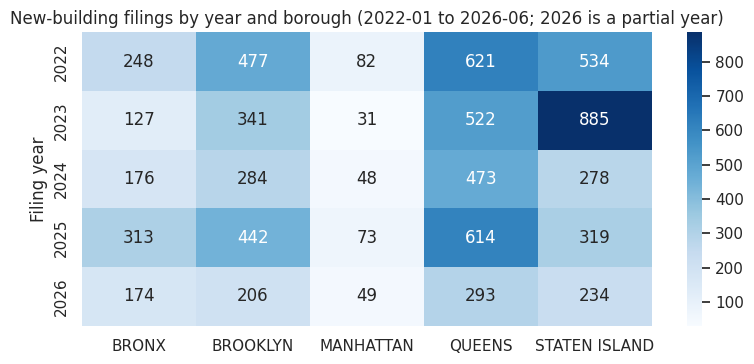

In [12]:
nb_window = housing[housing["is_new_building"] & housing["year_month"].between(PANEL_START, END_MONTH)]
coverage = pd.crosstab(nb_window["year"], nb_window["borough"])
display(coverage)

fig, ax = plt.subplots(figsize=(8, 3.8))
sns.heatmap(coverage, annot=True, fmt="d", cmap="Blues", ax=ax)
ax.set_title(f"New-building filings by year and borough ({PANEL_START} to {END_MONTH}; 2026 is a partial year)")
ax.set_xlabel(""); ax.set_ylabel("Filing year")
plt.tight_layout(); plt.show()

## 5. Give every crash a community district

### 5.1 The problem
Only about 24% of crashes carry a community board. The gap is not random: fatal crashes almost never have a board or coordinates. We therefore assign a district in **layers**, always preferring the most trustworthy source, and record where each value came from (`cd_source`):

1. **reported**: SIRTA's own community board (cleaned by Member 2);
2. **polygon**: the crash coordinates fall inside an official community district boundary (best method, independent of the housing data);
3. **nearest filing**: copy the district of the nearest housing filing within `ASSIGN_MAX_M` metres (fallback only for crashes the polygon step cannot place);
4. **unassigned**: no coordinates and no reported board; these crashes are still counted in the borough x month table.

Every method is **validated** on crashes whose district *is* reported, and a district that contradicts the crash's borough is rejected.

In [13]:
crashes = sirta[sirta["year_month"].between(PANEL_START, END_MONTH)].copy()
crashes["cd_reported"] = normalize_community_board(crashes["community_board"])
crashes["crash_type"] = np.where(crashes["is_fatal"], "Fatal crash", "Non-fatal serious-injury crash")

print(f"Crashes in the window: {len(crashes):,}")
print(f"  with a reported (valid) community district: {crashes.cd_reported.notna().mean():.1%}")
print(f"  with coordinates:                           {crashes.has_coordinates.mean():.1%}")
print(f"  fatal crashes with coordinates:             {crashes.loc[crashes.is_fatal, 'has_coordinates'].mean():.1%}")
print(f"  with a borough:                             {crashes.borough.notna().mean():.1%}")

Crashes in the window: 13,307
  with a reported (valid) community district: 24.3%
  with coordinates:                           81.7%
  fatal crashes with coordinates:             19.7%
  with a borough:                             99.7%


### 5.2 Layer 2: official boundary polygons
The notebook looks for `community_districts.geojson` next to the data (or in `outputs/`). If it is not there it tries to download the NYC Open Data **Community Districts** file (dataset `5crt-au7u`) and needs `geopandas`. If neither works (no internet, no geopandas) the notebook continues with the nearest-filing fallback and says so; **say in your report which method was used**.

To make it work offline: download the GeoJSON from the dataset page (Export -> GeoJSON), save it as `community_districts.geojson` in `outputs/`.

In [14]:
def load_cd_boundaries():
    """Return a GeoDataFrame [community_district, geometry] of the 59 residential districts, or None."""
    try:
        import geopandas as gpd
    except ImportError:
        print("geopandas is not installed (in Colab run: !pip install geopandas). Skipping the polygon layer.")
        return None

    sources = []
    try:
        sources.append(str(find_file(BOUNDARY_FILE)))
    except FileNotFoundError:
        pass
    sources += BOUNDARY_URLS

    gdf = None
    for source in sources:
        try:
            gdf = gpd.read_file(source)
            print("Boundaries loaded from:", source)
            break
        except Exception as error:                      # network, format or permission problems
            print(f"Could not read {source[:70]}... ({type(error).__name__})")
    if gdf is None:
        print("No boundary file available. Skipping the polygon layer.")
        return None

    id_col = next((c for c in gdf.columns if c.lower().replace("_", "") == "borocd"), None)
    if id_col is None:
        print("No BoroCD column found. Columns:", list(gdf.columns), "-> skipping the polygon layer.")
        return None
    gdf["community_district"] = normalize_community_board(gdf[id_col])
    gdf = gdf.dropna(subset=["community_district"]).to_crs(4326)     # drops parks / joint-interest areas
    print("Residential districts in the boundary file:", gdf["community_district"].nunique(), "(expected 59)")
    return gdf[["community_district", "geometry"]]

def assign_by_polygon(frame, boundaries):
    """District of the polygon that contains each crash point (NA when no coordinates or outside every polygon)."""
    import geopandas as gpd
    has_xy = frame["latitude"].notna() & frame["longitude"].notna()
    points = gpd.GeoDataFrame(index=frame.index[has_xy],
                              geometry=gpd.points_from_xy(frame.loc[has_xy, "longitude"], frame.loc[has_xy, "latitude"]), crs=4326)
    joined = gpd.sjoin(points, boundaries, how="left", predicate="within")
    joined = joined[~joined.index.duplicated(keep="first")]          # a point on a shared edge can match twice
    return joined["community_district"].reindex(frame.index).astype("Int64")

boundaries = load_cd_boundaries()
cd_polygon = assign_by_polygon(crashes, boundaries) if boundaries is not None else pd.Series(pd.NA, index=crashes.index, dtype="Int64")
print(f"Crashes placed by polygon: {cd_polygon.notna().sum():,} of {len(crashes):,}")

Boundaries loaded from: https://data.cityofnewyork.us/api/geospatial/5crt-au7u?method=export&format=GeoJSON
Residential districts in the boundary file: 59 (expected 59)
Crashes placed by polygon: 10,619 of 13,307


### 5.3 Layer 3: nearest housing filing (fallback)
Reference points are **all** cleaned housing filings with a valid district and coordinates (any job type), so the reference cloud is dense. A crash farther than `ASSIGN_MAX_M` from every filing stays unassigned. This layer uses the housing data to label crashes, so it is used only where the polygon layer cannot place a crash, and it is validated separately.

In [15]:
def to_xy_metres(lat, lon):
    """Simple local projection (good enough inside NYC) so distances are in metres."""
    lat, lon = np.asarray(lat, dtype=float), np.asarray(lon, dtype=float)
    return np.column_stack([(lon + 74.0) * 111_320 * np.cos(np.radians(40.7)), (lat - 40.7) * 110_540])

reference = housing.dropna(subset=["community_district", "latitude", "longitude"])
filing_tree = cKDTree(to_xy_metres(reference["latitude"], reference["longitude"]))
reference_cd = reference["community_district"].to_numpy(dtype="int64")

def assign_by_nearest_filing(frame, max_m=ASSIGN_MAX_M):
    """District of the nearest reference filing within max_m metres (NA otherwise)."""
    out = pd.Series(pd.NA, index=frame.index, dtype="Int64")
    has_xy = frame["latitude"].notna() & frame["longitude"].notna()
    dist, idx = filing_tree.query(to_xy_metres(frame.loc[has_xy, "latitude"], frame.loc[has_xy, "longitude"]),
                                  k=1, distance_upper_bound=max_m)
    found = np.isfinite(dist)
    out.loc[frame.index[has_xy][found]] = reference_cd[idx[found]]
    return out

cd_nearest = assign_by_nearest_filing(crashes)
print(f"Crashes placed by nearest filing: {cd_nearest.notna().sum():,} of {len(crashes):,}")

Crashes placed by nearest filing: 10,773 of 13,307


### 5.4 Validate the methods against the reported districts
Among crashes that **have** a reported district and coordinates, how often does each method return the same district? This is the evidence for using the method on the others (a fair test: the method never sees the reported value).

In [16]:
known = crashes["cd_reported"].notna() & crashes["has_coordinates"]
rows = []
for label, assigned in [("polygon", cd_polygon), ("nearest filing", cd_nearest)]:
    placed = known & assigned.notna()
    if placed.sum() == 0:
        rows.append({"method": label, "tested on": int(known.sum()), "placed": 0, "placed %": np.nan, "correct % of placed": np.nan})
        continue
    rows.append({"method": label, "tested on": int(known.sum()), "placed": int(placed.sum()),
                 "placed %": 100 * placed.sum() / known.sum(),
                 "correct % of placed": 100 * (assigned[placed] == crashes.loc[placed, "cd_reported"]).mean()})
validation_table = pd.DataFrame(rows).set_index("method")
display(validation_table)

,tested on,placed,placed %,correct % of placed
method,,,,
polygon,3104,3097,99.77,99.16
nearest filing,3104,3096,99.74,95.74


In [17]:
# Final assignment: reported -> polygon -> nearest filing -> unassigned
crashes["community_district"] = crashes["cd_reported"]
crashes["cd_source"] = np.where(crashes["cd_reported"].notna(), "reported", "unassigned")

def fill_from(candidate, label):
    """Fill still-missing districts from a candidate series, rejecting any that contradict the crash's borough."""
    ok_borough = crashes["borough"].isna() | (borough_of_cd(candidate) == crashes["borough"])
    need = crashes["community_district"].isna() & candidate.notna() & ok_borough
    crashes.loc[need, "community_district"] = candidate[need]
    crashes.loc[need, "cd_source"] = label
    rejected = int((crashes["community_district"].isna() & candidate.notna() & ~ok_borough).sum())
    print(f"{label:>15}: filled {int(need.sum()):,} crashes ({rejected} rejected for contradicting the crash borough)")

fill_from(cd_polygon, "polygon")
if USE_NEAREST_FILING_FALLBACK:
    fill_from(cd_nearest, "nearest filing")

# A reported district that contradicts the crash borough was already removed by Member 2; re-check
contradict = crashes["community_district"].notna() & crashes["borough"].notna() & (borough_of_cd(crashes["community_district"]) != crashes["borough"])
assert contradict.sum() == 0, "some crashes have a district in a different borough"

# Crashes with no borough but a district: take the borough from the district (deterministic, not a guess)
fill_boro = crashes["borough"].isna() & crashes["community_district"].notna()
crashes.loc[fill_boro, "borough"] = borough_of_cd(crashes.loc[fill_boro, "community_district"])
print(f"Boroughs derived from the district: {int(fill_boro.sum())}")

        polygon: filled 7,514 crashes (8 rejected for contradicting the crash borough)
 nearest filing: filled 186 crashes (2 rejected for contradicting the crash borough)
Boroughs derived from the district: 36


### 5.5 How complete is the result? (fatal vs non-fatal, and by borough)
This table is the honest picture of what the district-level analysis can and cannot say. Put it in the website's limitations section.

cd_source,reported,polygon,nearest filing,unassigned
crash_type,,,,
Fatal crash,2.40,18.20,0.80,78.70
Non-fatal serious-injury crash,26.20,59.70,1.50,12.60


cd_source,reported,polygon,nearest filing,unassigned
borough,,,,
BRONX,26.70,53.70,1.80,17.70
BROOKLYN,25.00,58.40,0.90,15.70
MANHATTAN,25.00,54.40,1.40,19.20
QUEENS,21.00,58.50,1.90,18.60
STATEN ISLAND,25.10,54.70,0.40,19.70
UNKNOWN,0.00,0.00,0.00,100.00


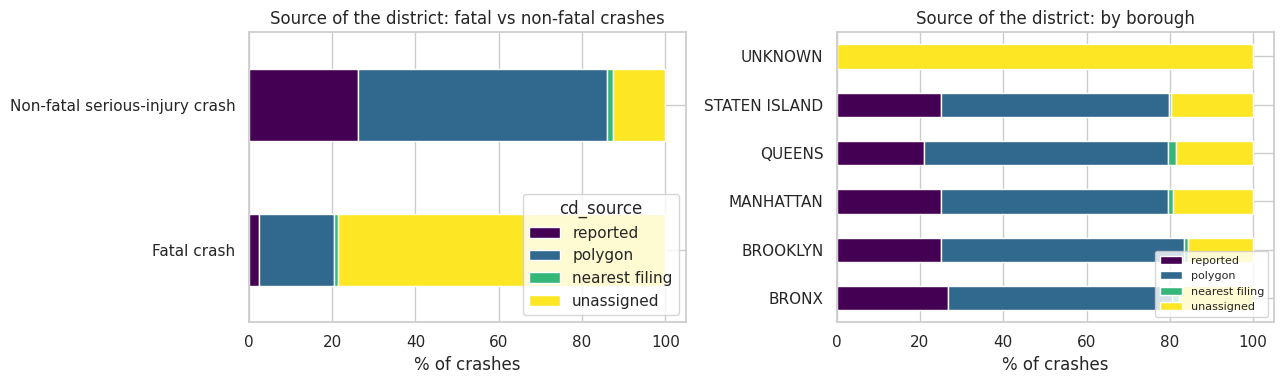

Crashes with a district: 10,938 of 13,307 (82.2%); fatal crashes: 21.3%


In [18]:
order = ["reported", "polygon", "nearest filing", "unassigned"]
by_type = (pd.crosstab(crashes["crash_type"], crashes["cd_source"], normalize="index") * 100).reindex(columns=order).fillna(0)
by_borough = (pd.crosstab(crashes["borough"].fillna("UNKNOWN"), crashes["cd_source"], normalize="index") * 100).reindex(columns=order).fillna(0)
display(by_type.round(1)); display(by_borough.round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
by_type.plot(kind="barh", stacked=True, ax=axes[0], colormap="viridis")
axes[0].set_title("Source of the district: fatal vs non-fatal crashes"); axes[0].set_xlabel("% of crashes"); axes[0].set_ylabel("")
by_borough.plot(kind="barh", stacked=True, ax=axes[1], colormap="viridis")
axes[1].set_title("Source of the district: by borough"); axes[1].set_xlabel("% of crashes"); axes[1].set_ylabel("")
axes[1].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

print(f"Crashes with a district: {crashes.community_district.notna().sum():,} of {len(crashes):,} "
      f"({crashes.community_district.notna().mean():.1%}); fatal crashes: {crashes.loc[crashes.is_fatal, 'community_district'].notna().mean():.1%}")

75.7% of SIRTA records have no reported community board — this is a known characteristic of the dataset, not a cleaning error. The field is populated from police reports and is inconsistently filled. We recover districts for 82% of all crashes using coordinates and a nearest-filing spatial assignment, reducing the unassigned share to 18%, which consists predominantly of fatal crashes that lack GPS coordinates.

## 6. Aggregate both sides to the common level

| Table | Level | Housing metric | Transportation metric |
|---|---|---|---|
| `cd_month` | community district x month | new-building filings, proposed units | crashes, severe injuries, fatalities, KSI |
| `cd_total` | community district (whole window) | same, summed | same, summed, plus rates |
| `borough_month` | borough x month | same as `cd_month` | **all** crashes, including those with no district |

* A **new building** is a job type exactly "New Building" (Member 1's `is_new_building`); each job is counted once (`job_number`).
* **KSI** = killed or seriously injured = severe injuries + fatalities.
* **Repeat-risk crashes** use SIRTA's `similar_ksi_3y` (deaths and severe injuries from similar crashes at the same location in the previous 3 years). They are included so Member 2's research question can use the same table.

In [19]:
# ---------------- Housing side
new_buildings = housing[housing["is_new_building"] & housing["year_month"].between(PANEL_START, END_MONTH)].copy()

def aggregate_housing(frame, keys):
    """New-building filings (unique jobs) and proposed dwelling units per group."""
    return (frame.groupby(keys, as_index=False)
                 .agg(new_filings=("job_number", "nunique"),
                      new_units=("proposed_dwelling_units", "sum")))

housing_cd_month = aggregate_housing(new_buildings.dropna(subset=["community_district"]), ["community_district", "year_month"])
housing_borough_month = aggregate_housing(new_buildings.dropna(subset=["borough"]), ["borough", "year_month"])

# ---------------- Transportation side
crashes["history_known"] = crashes["similar_ksi_3y"].notna()
crashes["repeat_location"] = crashes["similar_ksi_3y"].fillna(0) > 0

def aggregate_crashes(frame, keys):
    """Crash counts and casualty measures per group (one row per collision, so counts are never doubled)."""
    return (frame.groupby(keys, as_index=False)
                 .agg(crashes=("collision_id", "nunique"), severe_inj=("severe_inj", "sum"),
                      fatalities=("fatalities", "sum"), ksi=("ksi", "sum"),
                      history_known=("history_known", "sum"), repeat_location=("repeat_location", "sum")))

crash_cd_month = aggregate_crashes(crashes.dropna(subset=["community_district"]), ["community_district", "year_month"])
crash_borough_month = aggregate_crashes(crashes.dropna(subset=["borough"]), ["borough", "year_month"])

print("housing  cd x month rows:", len(housing_cd_month), "| borough x month rows:", len(housing_borough_month))
print("crashes  cd x month rows:", len(crash_cd_month), "| borough x month rows:", len(crash_borough_month))

housing  cd x month rows: 2100 | borough x month rows: 268
crashes  cd x month rows: 2901 | borough x month rows: 270


## 7. Integrate: join on a complete district x month grid

We first build the **full grid** (59 districts x every month in the window) and then left-join both aggregated tables onto it. A grid is needed because the aggregated tables only contain months with at least one event: without it, a quiet district would simply be missing instead of showing a zero.

Is a missing value after the join really a zero? **Yes for both sides**, because both sources cover the whole city for the whole window:
* no new-building filing in a district-month means no filing, not unknown;
* no recorded serious crash means no recorded serious crash in the crashes we could place in a district (see the coverage limits in 5.5: crashes with no district are not in this table).

In [20]:
months = pd.period_range(PANEL_START, END_MONTH, freq="M").astype(str)
grid = pd.MultiIndex.from_product([VALID_CDS, months], names=["community_district", "year_month"]).to_frame(index=False)
grid["community_district"] = grid["community_district"].astype("Int64")
print(f"Grid: {grid.community_district.nunique()} districts x {len(months)} months = {len(grid):,} rows")

# Raw join (before any filling) so the new missing values can be counted
cd_month_raw = (grid.merge(housing_cd_month, on=["community_district", "year_month"], how="left", validate="one_to_one")
                    .merge(crash_cd_month, on=["community_district", "year_month"], how="left", validate="one_to_one"))
missing_after_join = cd_month_raw.isna().sum()
display(missing_after_join[missing_after_join > 0].to_frame("missing after join"))
print(f"Share of district-months with no new-building filing: {cd_month_raw.new_filings.isna().mean():.1%}")
print(f"Share of district-months with no placed crash:         {cd_month_raw.crashes.isna().mean():.1%}")

Grid: 59 districts x 54 months = 3,186 rows


,missing after join
new_filings,1086
new_units,1086
crashes,285
severe_inj,285
fatalities,285
ksi,285
history_known,285
repeat_location,285


Share of district-months with no new-building filing: 34.1%
Share of district-months with no placed crash:         8.9%


## 8. Post-join cleaning (required)

| Problem | Decision | Why |
|---|---|---|
| New missing values from the join (months with no filing / no crash) | Fill with **0** | True zeros: both sources cover the whole city and window (see Section 7). Not imputed from neighbours. |
| Redundant / helper columns | None remain; `borough` is derived once from the district code | The two inputs would otherwise create `borough_x` / `borough_y`. |
| Data types | `community_district` Int64, counts int, `year_month` string, `year` int | Counts become floats after a left join with NaN; district codes must stay integers for the website filters. |
| Very large construction months | **Keep**, flag with `is_large_pipeline_month` | One huge project is real, and would be hidden by removing it. IQR (k = 3) on non-zero months. |
| Districts with few crashes | Keep in all tables; shares and rates are NaN, never 0, where the denominator is 0 | A rate of 0 would claim "safe" when it is "unknown". |
| Crashes with no district | Kept in `borough_month` only | They would otherwise vanish from the analysis. |

In [21]:
def post_join_clean(raw):
    """Apply the post-join cleaning rules to a joined panel and return (clean_panel, log)."""
    out = raw.copy()
    count_cols = ["new_filings", "new_units", "crashes", "severe_inj", "fatalities", "ksi", "history_known", "repeat_location"]
    log = {"nan_filled_with_zero": int(out[count_cols].isna().sum().sum())}

    out[count_cols] = out[count_cols].fillna(0)
    out[count_cols] = out[count_cols].astype("int64")             # counts are integers (float only because of NaN)
    out["community_district"] = out["community_district"].astype("int64")
    out["borough"] = borough_of_cd(out["community_district"])     # one borough column, derived from the key
    out["year"] = out["year_month"].str[:4].astype("int64")
    out["month"] = out["year_month"].str[5:7].astype("int64")

    # Flag extreme construction months (statistical outlier + domain sense: very large projects are real)
    nonzero_units = out.loc[out["new_units"] > 0, "new_units"]
    q1, q3 = nonzero_units.quantile([0.25, 0.75])
    fence = q3 + LARGE_PIPELINE_K * (q3 - q1)
    out["is_large_pipeline_month"] = out["new_units"] > fence
    log["large_pipeline_fence_units"] = float(fence)
    log["large_pipeline_months"] = int(out["is_large_pipeline_month"].sum())
    return out, log

cd_month, join_log = post_join_clean(cd_month_raw)
cd_month["cd_label"] = cd_month["borough"].map({"MANHATTAN": "MN", "BRONX": "BX", "BROOKLYN": "BK", "QUEENS": "QN", "STATEN ISLAND": "SI"}) \
                       + " " + (cd_month["community_district"] % 100).astype(str).str.zfill(2)
cd_month = cd_month[["community_district", "cd_label", "borough", "year_month", "year", "month",
                     "new_filings", "new_units", "is_large_pipeline_month",
                     "crashes", "severe_inj", "fatalities", "ksi", "history_known", "repeat_location"]]
print(join_log)
print("Missing values left:", int(cd_month.isna().sum().sum()))
print(cd_month.dtypes.to_string())
cd_month.head()

{'nan_filled_with_zero': 3882, 'large_pipeline_fence_units': 306.0, 'large_pipeline_months': 99}
Missing values left: 0
community_district          int64
cd_label                   object
borough                    object
year_month                 object
year                        int64
month                       int64
new_filings                 int64
new_units                   int64
is_large_pipeline_month      bool
crashes                     int64
severe_inj                  int64
fatalities                  int64
ksi                         int64
history_known               int64
repeat_location             int64


,community_district,cd_label,borough,year_month,year,month,new_filings,new_units,is_large_pipeline_month,crashes,severe_inj,fatalities,ksi,history_known,repeat_location
0,101,MN 01,MANHATTAN,2022-01,2022,1,0,0,False,1,1,0,1,1,0
1,101,MN 01,MANHATTAN,2022-02,2022,2,1,0,False,1,1,0,1,1,0
2,101,MN 01,MANHATTAN,2022-03,2022,3,0,0,False,0,0,0,0,0,0
3,101,MN 01,MANHATTAN,2022-04,2022,4,0,0,False,0,0,0,0,0,0
4,101,MN 01,MANHATTAN,2022-05,2022,5,0,0,False,1,1,0,1,1,0


### 8.1 Companion tables: district totals and borough x month
`cd_total` is the one-row-per-district table used by scatter plots and maps. Rates use **NaN** (not 0) where the denominator is 0.
`borough_month` is built on the **same** rules but from *all* crashes with a borough, so it includes fatal crashes that could not be placed in a district.

In [22]:
# ---------------- District totals (whole window)
cd_total = (cd_month.groupby(["community_district", "cd_label", "borough"], as_index=False)
                    .agg(new_filings=("new_filings", "sum"), new_units=("new_units", "sum"),
                         crashes=("crashes", "sum"), severe_inj=("severe_inj", "sum"), fatalities=("fatalities", "sum"),
                         ksi=("ksi", "sum"), history_known=("history_known", "sum"), repeat_location=("repeat_location", "sum")))
cd_total["log_new_units"] = np.log10(1 + cd_total["new_units"])
cd_total["ksi_per_1000_units"] = np.where(cd_total["new_units"] > 0, 1000 * cd_total["ksi"] / cd_total["new_units"].replace(0, np.nan), np.nan)
cd_total["repeat_share"] = np.where(cd_total["history_known"] > 0, cd_total["repeat_location"] / cd_total["history_known"].replace(0, np.nan), np.nan)
cd_total["ksi_per_filing"] = np.where(cd_total["new_filings"] > 0, cd_total["ksi"] / cd_total["new_filings"].replace(0, np.nan), np.nan)

# ---------------- Borough x month (all crashes with a borough)
borough_grid = pd.MultiIndex.from_product([list(BOROUGH_CODE.values()), months], names=["borough", "year_month"]).to_frame(index=False)
borough_month_raw = (borough_grid.merge(housing_borough_month, on=["borough", "year_month"], how="left", validate="one_to_one")
                                 .merge(crash_borough_month, on=["borough", "year_month"], how="left", validate="one_to_one"))
count_cols = ["new_filings", "new_units", "crashes", "severe_inj", "fatalities", "ksi", "history_known", "repeat_location"]
borough_month = borough_month_raw.copy()
borough_month[count_cols] = borough_month[count_cols].fillna(0).astype("int64")
borough_month["year"] = borough_month["year_month"].str[:4].astype("int64")
borough_month["month"] = borough_month["year_month"].str[5:7].astype("int64")

print("cd_total:", cd_total.shape, "| borough_month:", borough_month.shape, "| cd_month:", cd_month.shape)
display(cd_total.sort_values("new_units", ascending=False).head(8))

cd_total: (59, 15) | borough_month: (270, 12) | cd_month: (3186, 15)


,community_district,cd_label,borough,new_filings,new_units,crashes,severe_inj,fatalities,ksi,history_known,repeat_location,log_new_units,ksi_per_1000_units,repeat_share,ksi_per_filing
42,401,QN 01,QUEENS,160,8845,216,224,4,228,194,8,3.95,25.78,0.04,1.43
28,305,BK 05,BROOKLYN,177,7276,273,294,5,299,241,19,3.86,41.09,0.08,1.69
24,301,BK 01,BROOKLYN,206,6863,307,319,3,322,278,20,3.84,46.92,0.07,1.56
53,412,QN 12,QUEENS,344,6431,311,334,1,335,282,23,3.81,52.09,0.08,0.97
29,306,BK 06,BROOKLYN,113,5774,140,148,0,148,128,9,3.76,25.63,0.07,1.31
15,204,BX 04,BRONX,71,5660,233,249,3,252,217,27,3.75,44.52,0.12,3.55
18,207,BX 07,BRONX,96,5307,174,182,4,186,159,23,3.72,35.05,0.14,1.94
3,104,MN 04,MANHATTAN,36,4636,234,235,6,241,209,17,3.67,51.98,0.08,6.69


## 9. Validate the integrated data
The integrated tables must reconcile with the cleaned inputs. Any difference must be explained (crashes with no district, filings with no district), never ignored.

In [23]:
checks = []
def add_check(name, passed, detail):
    checks.append({"check": name, "passed": bool(passed), "detail": detail})

# Structure
add_check("59 districts in cd_month", cd_month["community_district"].nunique() == 59, cd_month["community_district"].nunique())
add_check("grid is complete (59 x months)", len(cd_month) == 59 * len(months), f"{len(cd_month):,} rows")
add_check("no duplicate district-month keys", not cd_month.duplicated(["community_district", "year_month"]).any(), "")
add_check("no duplicate borough-month keys", not borough_month.duplicated(["borough", "year_month"]).any(), "")
add_check("no missing values in cd_month", cd_month.isna().sum().sum() == 0, "")
add_check("no missing values in borough_month", borough_month.isna().sum().sum() == 0, "")
add_check("no negative counts", (cd_month[["new_filings", "new_units", "crashes", "ksi"]] >= 0).all().all(), "")

# Reconciliation with the cleaned inputs
nb_with_cd = new_buildings.dropna(subset=["community_district"])
add_check("new-building filings: cd_month = cleaned data (rows with a district)",
          cd_month["new_filings"].sum() == nb_with_cd["job_number"].nunique(),
          f"{cd_month['new_filings'].sum():,} vs {nb_with_cd['job_number'].nunique():,}")
add_check("proposed units: cd_month = cleaned data (rows with a district)",
          np.isclose(cd_month["new_units"].sum(), nb_with_cd["proposed_dwelling_units"].sum()),
          f"{cd_month['new_units'].sum():,.0f} vs {nb_with_cd['proposed_dwelling_units'].sum():,.0f}")
placed = crashes.dropna(subset=["community_district"])
add_check("crashes: cd_month = crashes with a district", cd_month["crashes"].sum() == placed["collision_id"].nunique(),
          f"{cd_month['crashes'].sum():,} vs {placed['collision_id'].nunique():,}")
add_check("KSI: cd_month = crashes with a district", cd_month["ksi"].sum() == placed["ksi"].sum(),
          f"{cd_month['ksi'].sum():,} vs {placed['ksi'].sum():,}")
with_borough = crashes.dropna(subset=["borough"])
add_check("crashes: borough_month = crashes with a borough", borough_month["crashes"].sum() == with_borough["collision_id"].nunique(),
          f"{borough_month['crashes'].sum():,} vs {with_borough['collision_id'].nunique():,}")
add_check("borough_month holds more crashes than cd_month (fatal crashes with no district)",
          borough_month["crashes"].sum() >= cd_month["crashes"].sum(),
          f"{borough_month['crashes'].sum():,} vs {cd_month['crashes'].sum():,}")
add_check("cd_total sums match cd_month", cd_total["ksi"].sum() == cd_month["ksi"].sum() and cd_total["new_units"].sum() == cd_month["new_units"].sum(), "")
display(pd.DataFrame(checks))
assert all(c["passed"] for c in checks), "A validation check failed; read the table above."

,check,passed,detail
0,59 districts in cd_month,True,59
1,grid is complete (59 x months),True,"3,186 rows"
2,no duplicate district-month keys,True,
3,no duplicate borough-month keys,True,
4,no missing values in cd_month,True,
5,no missing values in borough_month,True,
6,no negative counts,True,
7,new-building filings: cd_month = cleaned data ...,True,"7,817 vs 7,817"
8,proposed units: cd_month = cleaned data (rows ...,True,"142,251 vs 142,251"
9,crashes: cd_month = crashes with a district,True,"10,938 vs 10,938"


### 9.1 Validation charts

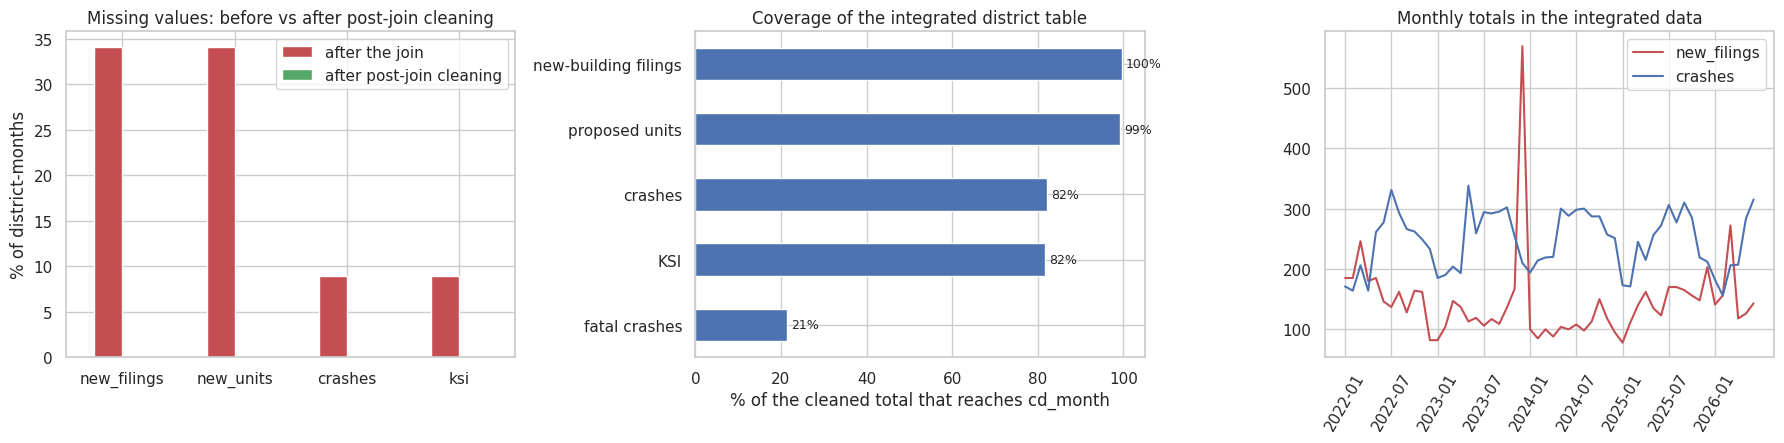

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))

# (a) What the join added: missing values before and after post-join cleaning
before = cd_month_raw[["new_filings", "new_units", "crashes", "ksi"]].isna().mean() * 100
after = cd_month[["new_filings", "new_units", "crashes", "ksi"]].isna().mean() * 100
pd.DataFrame({"after the join": before, "after post-join cleaning": after}).plot(kind="bar", ax=axes[0], color=["#C44E52", "#55A868"])
axes[0].set_title("Missing values: before vs after post-join cleaning"); axes[0].set_ylabel("% of district-months"); axes[0].tick_params(axis="x", rotation=0)

# (b) How much of each total reaches the district table
share = pd.Series({
    "new-building filings": cd_month["new_filings"].sum() / new_buildings["job_number"].nunique(),
    "proposed units": cd_month["new_units"].sum() / new_buildings["proposed_dwelling_units"].sum(),
    "crashes": cd_month["crashes"].sum() / len(crashes),
    "KSI": cd_month["ksi"].sum() / crashes["ksi"].sum(),
    "fatal crashes": crashes.loc[crashes.is_fatal, "community_district"].notna().mean(),
}) * 100
share.sort_values().plot(kind="barh", ax=axes[1], color="#4C72B0")
axes[1].set_xlim(0, 105); axes[1].set_xlabel("% of the cleaned total that reaches cd_month")
axes[1].set_title("Coverage of the integrated district table")
for i, v in enumerate(share.sort_values()):
    axes[1].text(v + 1, i, f"{v:.0f}%", va="center", fontsize=9)

# (c) Time coverage: both series over the whole window
monthly_check = borough_month.groupby("year_month")[["new_filings", "crashes"]].sum()
monthly_check.plot(ax=axes[2], color=["#C44E52", "#4C72B0"])
axes[2].set_title("Monthly totals in the integrated data"); axes[2].set_xlabel("")
axes[2].set_xticks(range(0, len(monthly_check), 6)); axes[2].set_xticklabels(monthly_check.index[::6], rotation=60)
plt.tight_layout(); plt.show()

## 10. My research questions (Member 3)

Both questions use the integrated district tables and describe **associations**, not causes.

### Research question 1
**Do community districts with larger new-building pipelines (more proposed dwelling units, 2022 onward) also record more killed-or-seriously-injured (KSI) people on their streets, and does the pattern hold inside each borough?**

*Why it matters:* if the districts that are adding the most homes already have the most severe crashes, street safety projects can be timed with construction instead of after the new residents arrive.

*Method:* Spearman rank correlation (counts are skewed) between `new_units` and `ksi` per district, overall and within each borough (borough is a major confounder: road type, density and traffic differ). Large districts have more of everything, so the result is a starting point, not a finding about construction.

All 59 districts: Spearman rho = 0.26 (p = 0.048)


,districts,spearman_rho,p_value
borough,,,
BRONX,12,0.52,0.08
BROOKLYN,18,0.22,0.39
MANHATTAN,12,0.82,0.00
QUEENS,14,0.05,0.86
STATEN ISLAND,3,0.50,0.67


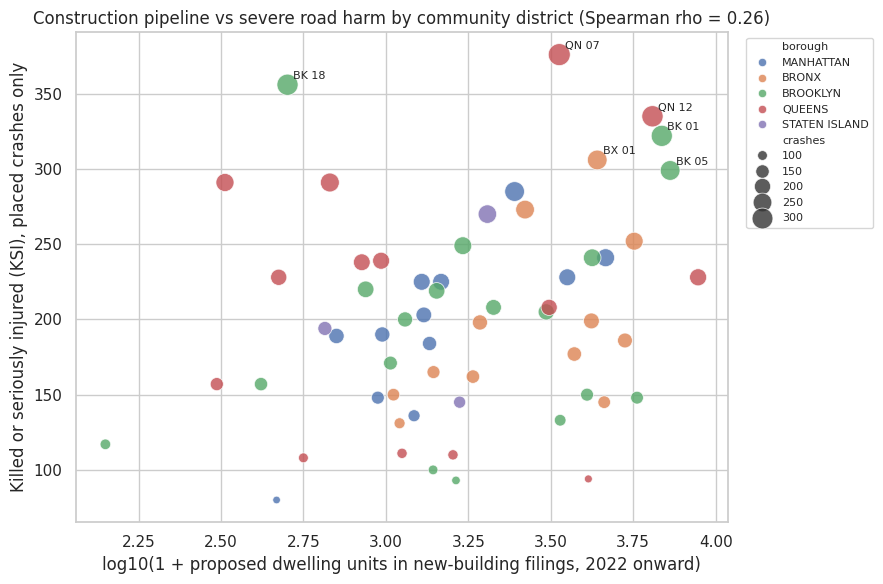

In [25]:
rq1 = cd_total.copy()
rho_all, p_all = stats.spearmanr(rq1["new_units"], rq1["ksi"])
print(f"All {len(rq1)} districts: Spearman rho = {rho_all:.2f} (p = {p_all:.3f})")

within = []
for borough_name, group in rq1.groupby("borough"):
    rho, p = stats.spearmanr(group["new_units"], group["ksi"])
    within.append({"borough": borough_name, "districts": len(group), "spearman_rho": rho, "p_value": p})
within = pd.DataFrame(within).set_index("borough")
display(within)

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=rq1, x="log_new_units", y="ksi", hue="borough", size="crashes", sizes=(30, 250), alpha=0.8, ax=ax)
for _, row in rq1.nlargest(6, "ksi").iterrows():
    ax.annotate(row["cd_label"], (row["log_new_units"], row["ksi"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("log10(1 + proposed dwelling units in new-building filings, 2022 onward)")
ax.set_ylabel("Killed or seriously injured (KSI), placed crashes only")
ax.set_title(f"Construction pipeline vs severe road harm by community district (Spearman rho = {rho_all:.2f})")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

### Research question 2
**Do months with more new-building filings in a district tend to be followed by more (or fewer) severe-injury crashes in that same district in the following months?**

*Why it matters:* construction brings trucks, street works and, later, residents. If severe crashes rise a few months after filing peaks, planners can add safety measures early. If nothing shows up, that is useful too.

*Method:* for each lag from 0 to 6 months we correlate new-building filings in month *t - lag* with KSI in month *t*, after **removing each district's own average** (so we compare a district with itself over time and not busy districts with quiet ones). Spearman rank correlation, because most district-months are zero.

*Caution:* SIRTA counts are small, there are many zeros, and filings are not construction starts. Treat this as a screening test.

,spearman_rho,p_value,n_district_months
lag_months,,,
0,0.01,0.52,3186
1,0.01,0.63,3127
2,-0.00,0.90,3068
3,0.04,0.04,3009
4,0.01,0.62,2950
5,0.02,0.33,2891
6,0.03,0.08,2832


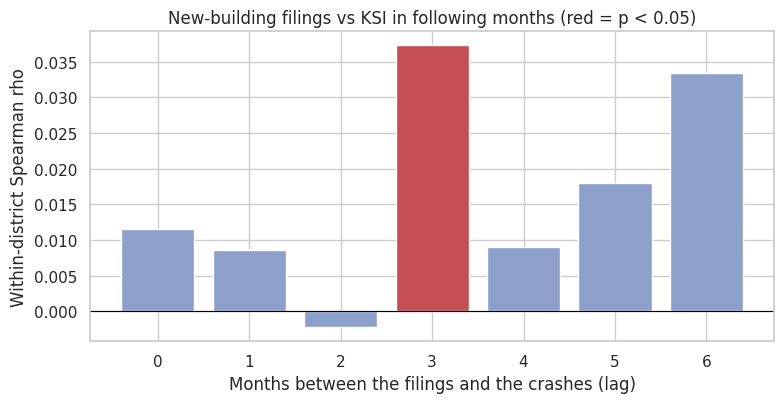

In [26]:
panel = cd_month.sort_values(["community_district", "year_month"]).copy()
by_cd = panel.groupby("community_district")

def within_district_demean(series):
    """Subtract each district's own mean, so the comparison is a district against itself over time."""
    return series - series.groupby(panel["community_district"]).transform("mean")

panel["ksi_demeaned"] = within_district_demean(panel["ksi"])
rows = []
for lag in LAG_MONTHS:
    lagged = by_cd["new_filings"].shift(lag)
    usable = lagged.notna()
    x = lagged[usable] - lagged[usable].groupby(panel.loc[usable, "community_district"]).transform("mean")
    y = panel.loc[usable, "ksi_demeaned"]
    rho, p = stats.spearmanr(x, y)
    rows.append({"lag_months": lag, "spearman_rho": rho, "p_value": p, "n_district_months": int(usable.sum())})
lag_results = pd.DataFrame(rows).set_index("lag_months")
display(lag_results)

fig, ax = plt.subplots(figsize=(8, 4.2))
colors = ["#C44E52" if p < 0.05 else "#8DA0CB" for p in lag_results["p_value"]]
ax.bar(lag_results.index.astype(str), lag_results["spearman_rho"], color=colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Months between the filings and the crashes (lag)")
ax.set_ylabel("Within-district Spearman rho")
ax.set_title("New-building filings vs KSI in following months (red = p < 0.05)")
plt.tight_layout(); plt.show()

In [27]:
# Auto-written summary: re-run this cell after any change and copy the sentences into your findings
best_lag = lag_results["spearman_rho"].abs().idxmax()
print("RQ1:", f"across {len(rq1)} districts, rank correlation between proposed units and KSI is {rho_all:.2f} (p = {p_all:.3f});",
      "within boroughs it ranges from {:.2f} to {:.2f}.".format(within["spearman_rho"].min(), within["spearman_rho"].max()))
print("RQ2:", f"the strongest within-district link is at a lag of {best_lag} months (rho = {lag_results.loc[best_lag, 'spearman_rho']:.2f}, "
      f"p = {lag_results.loc[best_lag, 'p_value']:.3f}); {int((lag_results.p_value < 0.05).sum())} of {len(lag_results)} lags are significant at 5%.")
print(f"Both use only crashes that could be placed in a district ({crashes.community_district.notna().mean():.0%} of crashes; "
      f"{crashes.loc[crashes.is_fatal, 'community_district'].notna().mean():.0%} of fatal crashes).")

RQ1: across 59 districts, rank correlation between proposed units and KSI is 0.26 (p = 0.048); within boroughs it ranges from 0.05 to 0.82.
RQ2: the strongest within-district link is at a lag of 3 months (rho = 0.04, p = 0.041); 1 of 7 lags are significant at 5%.
Both use only crashes that could be placed in a district (82% of crashes; 21% of fatal crashes).


## 11. Export for the team (Members 4, 5 and 6)
Column names are now **frozen**: the website and everyone's charts read these files. Tell Members 4-6 before changing any name.

In [28]:
DATA_DICTIONARY = pd.DataFrame([
    ("community_district", "all district tables", "Int", "Community district code: borough digit + 2-digit district (e.g. 301 = Brooklyn CD 1)"),
    ("cd_label", "cd_month, cd_total", "text", "Short label for charts, e.g. 'BK 01'"),
    ("borough", "all tables", "text", "MANHATTAN, BRONX, BROOKLYN, QUEENS or STATEN ISLAND (uppercase)"),
    ("year_month", "cd_month, borough_month", "text", "YYYY-MM; the time key"),
    ("year, month", "cd_month, borough_month", "int", "Parts of year_month"),
    ("new_filings", "all tables", "int", "New-building job filings (unique jobs; job type exactly 'New Building'); filings, not completed buildings"),
    ("new_units", "all tables", "int", "Sum of proposed dwelling units in those filings (values above 5,000 per filing were set to missing by Member 1)"),
    ("is_large_pipeline_month", "cd_month", "bool", "True when new_units is above Q3 + 3 x IQR of non-zero months (flagged, not removed)"),
    ("crashes", "all tables", "int", "SIRTA crashes with at least one severe injury or death"),
    ("severe_inj, fatalities", "all tables", "int", "Severe injuries / deaths in those crashes"),
    ("ksi", "all tables", "int", "Killed or seriously injured = severe_inj + fatalities"),
    ("history_known, repeat_location", "all tables", "int", "Crashes with a known 3-year history of similar severe crashes at the location / those with at least one"),
    ("log_new_units", "cd_total", "float", "log10(1 + new_units), for skewed scatter plots"),
    ("ksi_per_1000_units", "cd_total", "float", "KSI per 1,000 proposed units; NaN where new_units = 0"),
    ("ksi_per_filing", "cd_total", "float", "KSI per new-building filing; NaN where there are no filings"),
    ("repeat_share", "cd_total", "float", "repeat_location / history_known; NaN where history_known = 0"),
], columns=["column", "table(s)", "type", "meaning"])

exports = {"cd_month.csv": cd_month, "cd_total.csv": cd_total, "borough_month.csv": borough_month,
           "crashes_with_district.csv": crashes.drop(columns=["crash_type"]), "data_dictionary.csv": DATA_DICTIONARY}
for name, table in exports.items():
    table.to_csv(OUT_DIR / name, index=False)
    print(f"Saved {OUT_DIR / name}  {table.shape}")
display(DATA_DICTIONARY)

Saved outputs/cd_month.csv  (3186, 15)
Saved outputs/cd_total.csv  (59, 15)
Saved outputs/borough_month.csv  (270, 12)
Saved outputs/crashes_with_district.csv  (13307, 33)
Saved outputs/data_dictionary.csv  (16, 4)


,column,table(s),type,meaning
0,community_district,all district tables,Int,Community district code: borough digit + 2-dig...
1,cd_label,"cd_month, cd_total",text,"Short label for charts, e.g. 'BK 01'"
2,borough,all tables,text,"MANHATTAN, BRONX, BROOKLYN, QUEENS or STATEN I..."
3,year_month,"cd_month, borough_month",text,YYYY-MM; the time key
4,"year, month","cd_month, borough_month",int,Parts of year_month
5,new_filings,all tables,int,New-building job filings (unique jobs; job typ...
6,new_units,all tables,int,Sum of proposed dwelling units in those filing...
7,is_large_pipeline_month,cd_month,bool,True when new_units is above Q3 + 3 x IQR of n...
8,crashes,all tables,int,SIRTA crashes with at least one severe injury ...
9,"severe_inj, fatalities",all tables,int,Severe injuries / deaths in those crashes


## 12. Integration methodology, limitations and contribution

### Methodology in one paragraph
Both cleaned datasets were aggregated to **community district x month** (59 districts, 2022-01 to the last complete SIRTA month). Housing already carried a valid district for 99.3% of filings; for crashes the district was taken in this order of trust: the crash's own reported board, then the official boundary polygon containing the crash location, then (fallback) the district of the nearest housing filing within 300 m. Every method was validated against reported districts. The two tables were joined on a complete district x month grid and missing cells set to zero because both sources cover the whole city. The same measures were also aggregated to district totals and to borough x month (all crashes).

### Limitations (use these in the website's story section)
* **Fatal crashes are under-represented in the district tables**: very few have coordinates or a community board. Borough x month is the only table that contains every crash.
* **Filings are not buildings.** A DOB NOW new-building filing is a permit application, not a completed building or a new resident. Proposed units are plans.
* **DOB NOW phase-in:** counts can reflect when filings moved into the system, not real construction activity (see 4.1).
* **Small counts:** SIRTA holds only serious-injury crashes, so most district-months are zero; results are noisy.
* **No population or traffic denominators:** big districts have more of everything. Rates here are per proposed unit, not per resident or per vehicle.
* **Association, not causation:** nothing here shows that construction causes crashes (or the reverse); boroughs, density and road type confound both.

### My contribution (for the README)
* Chose the integration level and join key, with alternatives and justification.
* Standardised the community-district key on the housing side and built the layered district assignment for crashes (reported, polygon, nearest filing) with validation.
* Aggregated both datasets, built the complete-grid join, and performed and documented the post-join cleaning.
* Validated the integrated data (structure checks, reconciliation with the inputs, coverage charts).
* Exported `cd_month.csv`, `cd_total.csv`, `borough_month.csv`, `crashes_with_district.csv` and the data dictionary for Members 4-6.
* Research questions 1 and 2 above, with one visualization each.